## 4 Hourly Data

In [1]:
import pandas as pd
import glob

In [7]:
files = glob.glob("/Users/mac/Desktop/Upwork/GoldSignalGenerator/Artifacts/HourlyData/XAU-USD_Hour_*.csv")
df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

In [8]:
df.head()

,UTC,Open,High,Low,Close,Volume
0,01.05.2022 22:00:00.000 UTC,1895.635,1899.788,1895.338,1897.118,2.325925
1,02.05.2022 00:00:00.000 UTC,1897.118,1898.373,1884.368,1888.448,7.341360
2,02.05.2022 04:00:00.000 UTC,1888.428,1888.438,1882.623,1884.147,6.915950
3,02.05.2022 08:00:00.000 UTC,1884.137,1885.398,1875.713,1876.013,8.140070
4,02.05.2022 12:00:00.000 UTC,1875.939,1876.598,1854.468,1869.994,18.598250


In [9]:
df["UTC"] = pd.to_datetime(
    df["UTC"], 
    format="%d.%m.%Y %H:%M:%S.%f UTC"
)

df = df.sort_values("UTC", ascending=True).reset_index(drop=True)
df.rename(columns={'UTC':'datetime'}, inplace=True)

In [10]:
print(df.head())

             datetime      Open      High       Low     Close    Volume
0 2022-01-02 23:00:00  1828.604  1831.624  1827.898  1828.354   0.69291
1 2022-01-03 00:00:00  1828.294  1831.458  1824.068  1825.618   3.84660
2 2022-01-03 04:00:00  1825.618  1825.854  1820.908  1824.148   3.47935
3 2022-01-03 08:00:00  1824.138  1827.414  1821.238  1822.875   4.45034
4 2022-01-03 12:00:00  1822.875  1823.108  1799.678  1801.838  15.14813


In [11]:
print(df.tail())

                datetime      Open      High       Low     Close    Volume
5953 2025-09-30 04:00:00  3864.555  3871.505  3839.195  3843.645  11.46528
5954 2025-09-30 08:00:00  3843.675  3847.035  3792.875  3815.045  10.34700
5955 2025-09-30 12:00:00  3815.045  3854.435  3808.745  3838.765  13.51321
5956 2025-09-30 16:00:00  3838.615  3860.535  3837.648  3858.798   7.12472
5957 2025-09-30 20:00:00  3858.898  3862.865  3850.365  3862.765   2.34693


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5958 entries, 0 to 5957
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   datetime  5958 non-null   datetime64[ns]
 1   Open      5958 non-null   float64       
 2   High      5958 non-null   float64       
 3   Low       5958 non-null   float64       
 4   Close     5958 non-null   float64       
 5   Volume    5958 non-null   float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 279.4 KB


In [22]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Load your 4-hour data
# df = pd.read_csv('your_4hour_data.csv')
df['datetime'] = pd.to_datetime(df['datetime'])
df = df.sort_values('datetime').reset_index(drop=True)

print(f"Total candles: {len(df)}")
print(f"Date range: {df['datetime'].min()} to {df['datetime'].max()}")
print(f"Duration: {(df['datetime'].max() - df['datetime'].min()).days} days")
print(f"Missing values: {df.isnull().sum().sum()}")

# Time features
df['hour'] = df['datetime'].dt.hour
df['day_of_week'] = df['datetime'].dt.dayofweek
df['month'] = df['datetime'].dt.month
df['year'] = df['datetime'].dt.year

Total candles: 5858
Date range: 2022-01-24 20:00:00 to 2025-09-30 16:00:00
Duration: 1344 days
Missing values: 0


In [23]:
def add_technical_indicators(df):
    """Add technical indicators for 4-hour timeframe"""
    df = df.copy()
    
    # Moving Averages
    df['SMA_10'] = df['Close'].rolling(window=10).mean()  # 40 hours
    df['SMA_20'] = df['Close'].rolling(window=20).mean()  # 80 hours (~3 days)
    df['SMA_50'] = df['Close'].rolling(window=50).mean()  # 200 hours (~8 days)
    df['SMA_100'] = df['Close'].rolling(window=100).mean()  # 400 hours (~17 days)
    
    df['EMA_10'] = df['Close'].ewm(span=10, adjust=False).mean()
    df['EMA_20'] = df['Close'].ewm(span=20, adjust=False).mean()
    df['EMA_50'] = df['Close'].ewm(span=50, adjust=False).mean()
    
    # RSI
    delta = df['Close'].diff()
    gain = (delta.where(delta > 0, 0)).rolling(window=14).mean()
    loss = (-delta.where(delta < 0, 0)).rolling(window=14).mean()
    rs = gain / loss
    df['RSI'] = 100 - (100 / (1 + rs))
    
    # MACD
    ema_12 = df['Close'].ewm(span=12, adjust=False).mean()
    ema_26 = df['Close'].ewm(span=26, adjust=False).mean()
    df['MACD'] = ema_12 - ema_26
    df['MACD_Signal'] = df['MACD'].ewm(span=9, adjust=False).mean()
    df['MACD_Histogram'] = df['MACD'] - df['MACD_Signal']
    
    # Bollinger Bands
    df['BB_Middle'] = df['Close'].rolling(window=20).mean()
    bb_std = df['Close'].rolling(window=20).std()
    df['BB_Upper'] = df['BB_Middle'] + (bb_std * 2)
    df['BB_Lower'] = df['BB_Middle'] - (bb_std * 2)
    df['BB_Width'] = (df['BB_Upper'] - df['BB_Lower']) / df['BB_Middle']
    
    # ATR (for stop loss)
    high_low = df['High'] - df['Low']
    high_close = abs(df['High'] - df['Close'].shift())
    low_close = abs(df['Low'] - df['Close'].shift())
    tr = pd.concat([high_low, high_close, low_close], axis=1).max(axis=1)
    df['ATR'] = tr.rolling(window=14).mean()
    
    # Momentum
    df['ROC'] = ((df['Close'] - df['Close'].shift(10)) / df['Close'].shift(10)) * 100
    df['Momentum'] = df['Close'] - df['Close'].shift(10)
    
    # Volume
    df['Volume_MA'] = df['Volume'].rolling(window=20).mean()
    df['Volume_Ratio'] = df['Volume'] / df['Volume_MA']
    
    # Price position
    df['Price_to_SMA20'] = (df['Close'] - df['SMA_20']) / df['SMA_20']
    df['Price_to_SMA50'] = (df['Close'] - df['SMA_50']) / df['SMA_50']
    
    # Trend indicators
    df['SMA10_above_SMA20'] = (df['SMA_10'] > df['SMA_20']).astype(int)
    df['SMA20_above_SMA50'] = (df['SMA_20'] > df['SMA_50']).astype(int)
    df['Price_above_SMA50'] = (df['Close'] > df['SMA_50']).astype(int)
    
    # Volatility
    df['Returns'] = df['Close'].pct_change()
    df['Volatility'] = df['Returns'].rolling(window=20).std()
    
    return df

df = add_technical_indicators(df)
df = df.dropna()

print(f"\nAfter adding indicators: {len(df)} candles")
print(f"Features created: {df.shape[1]} columns")


After adding indicators: 5759 candles
Features created: 40 columns


In [15]:
def create_target(df, forward_periods=1, threshold=0.003):
    """
    Create target for NEXT candle (4 hours ahead)
    threshold = 0.3% minimum move to consider tradeable
    """
    df = df.copy()
    
    # Look 1 period ahead (4 hours)
    df['Future_Close'] = df['Close'].shift(-forward_periods)
    df['Future_Return'] = (df['Future_Close'] - df['Close']) / df['Close']
    
    # Classify
    def classify(ret):
        if pd.isna(ret):
            return np.nan
        elif ret > threshold:
            return 1  # BUY
        elif ret < -threshold:
            return -1  # SELL
        else:
            return 0  # HOLD
    
    df['Target'] = df['Future_Return'].apply(classify)
    
    return df

df = create_target(df, forward_periods=1, threshold=0.003)
df = df.dropna()

print("\nTarget Distribution:")
print(df['Target'].value_counts().sort_index())
print("\nPercentages:")
print(df['Target'].value_counts(normalize=True).sort_index() * 100)


Target Distribution:
Target
-1.0     766
 0.0    4228
 1.0     864
Name: count, dtype: int64

Percentages:
Target
-1.0    13.076135
 0.0    72.174804
 1.0    14.749061
Name: proportion, dtype: float64


In [24]:
df.head()

,datetime,Open,High,Low,Close,Volume,hour,day_of_week,month,year,...,Price_to_SMA20,Price_to_SMA50,SMA10_above_SMA20,SMA20_above_SMA50,Price_above_SMA50,Returns,Volatility,Future_Close,Future_Return,Target
99,2022-02-15 20:00:00,1854.328,1856.147,1851.398,1852.848,2.866620,20,1,2,2022,...,0.000248,0.010587,1,1,1,-0.000793,0.004700,1852.638,-0.000113,0.0
100,2022-02-16 00:00:00,1852.848,1853.038,1850.188,1852.638,6.022710,0,2,2,2022,...,-0.000565,0.009963,1,1,1,-0.000113,0.004675,1855.108,0.001333,0.0
101,2022-02-16 04:00:00,1852.638,1856.758,1852.108,1855.108,5.114260,4,2,2,2022,...,-0.000049,0.010782,1,1,1,0.001333,0.004659,1856.288,0.000636,0.0
102,2022-02-16 08:00:00,1855.108,1859.528,1853.858,1856.288,7.953960,8,2,2,2022,...,-0.000227,0.010925,1,1,1,0.000636,0.004659,1862.554,0.003376,1.0
103,2022-02-16 12:00:00,1856.288,1864.758,1851.338,1862.554,16.259854,12,2,2,2022,...,0.002195,0.013688,1,1,1,0.003376,0.004693,1870.298,0.004158,1.0


In [25]:
df.info(max_cols=100)

<class 'pandas.core.frame.DataFrame'>
Index: 5759 entries, 99 to 5857
Data columns (total 40 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   datetime           5759 non-null   datetime64[ns]
 1   Open               5759 non-null   float64       
 2   High               5759 non-null   float64       
 3   Low                5759 non-null   float64       
 4   Close              5759 non-null   float64       
 5   Volume             5759 non-null   float64       
 6   hour               5759 non-null   int32         
 7   day_of_week        5759 non-null   int32         
 8   month              5759 non-null   int32         
 9   year               5759 non-null   int32         
 10  SMA_10             5759 non-null   float64       
 11  SMA_20             5759 non-null   float64       
 12  SMA_50             5759 non-null   float64       
 13  SMA_100            5759 non-null   float64       
 14  EMA_10      

In [26]:
df["Target"].value_counts()

Target
 0.0    4149
 1.0     853
-1.0     757
Name: count, dtype: int64

In [27]:
from prophet import Prophet

def add_prophet_features(df):
    try:
        prophet_df = df[['datetime', 'Close']].rename(columns={'datetime': 'ds', 'Close': 'y'})
        prophet_df['ds'] = pd.to_datetime(prophet_df['ds']).dt.tz_localize(None)

        model = Prophet(
            daily_seasonality=True,
            weekly_seasonality=True,
            yearly_seasonality=False,
            seasonality_mode='additive',
            interval_width=0.8,
            changepoint_prior_scale=0.05,
            seasonality_prior_scale=0.1
        )
        model.fit(prophet_df)

        forecast = model.predict(prophet_df[['ds']])
        forecast_features = forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper', 'trend']]
        df = df.merge(forecast_features, left_on='datetime', right_on='ds', how='left').drop(columns=['ds'])

        return df

    except Exception as e:
        print(f"Prophet failed: {e}")
        return df


Importing plotly failed. Interactive plots will not work.


In [28]:
df = add_prophet_features(df)

00:27:22 - cmdstanpy - INFO - Chain [1] start processing
00:27:27 - cmdstanpy - INFO - Chain [1] done processing


In [29]:
df.head()

,datetime,Open,High,Low,Close,Volume,hour,day_of_week,month,year,...,Price_above_SMA50,Returns,Volatility,Future_Close,Future_Return,Target,yhat,yhat_lower,yhat_upper,trend
0,2022-02-15 20:00:00,1854.328,1856.147,1851.398,1852.848,2.866620,20,1,2,2022,...,1,-0.000793,0.004700,1852.638,-0.000113,0.0,1924.108461,1849.728019,1994.112941,1923.286264
1,2022-02-16 00:00:00,1852.848,1853.038,1850.188,1852.638,6.022710,0,2,2,2022,...,1,-0.000113,0.004675,1855.108,0.001333,0.0,1923.618937,1850.763049,1994.328451,1923.381986
2,2022-02-16 04:00:00,1852.638,1856.758,1852.108,1855.108,5.114260,4,2,2,2022,...,1,0.001333,0.004659,1856.288,0.000636,0.0,1923.527169,1855.262690,1997.478042,1923.477708
3,2022-02-16 08:00:00,1855.108,1859.528,1853.858,1856.288,7.953960,8,2,2,2022,...,1,0.000636,0.004659,1862.554,0.003376,1.0,1923.705105,1848.921284,1993.056839,1923.573430
4,2022-02-16 12:00:00,1856.288,1864.758,1851.338,1862.554,16.259854,12,2,2,2022,...,1,0.003376,0.004693,1870.298,0.004158,1.0,1923.391428,1848.622603,1995.074750,1923.669152


In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5759 entries, 0 to 5758
Data columns (total 44 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   datetime           5759 non-null   datetime64[ns]
 1   Open               5759 non-null   float64       
 2   High               5759 non-null   float64       
 3   Low                5759 non-null   float64       
 4   Close              5759 non-null   float64       
 5   Volume             5759 non-null   float64       
 6   hour               5759 non-null   int32         
 7   day_of_week        5759 non-null   int32         
 8   month              5759 non-null   int32         
 9   year               5759 non-null   int32         
 10  SMA_10             5759 non-null   float64       
 11  SMA_20             5759 non-null   float64       
 12  SMA_50             5759 non-null   float64       
 13  SMA_100            5759 non-null   float64       
 14  EMA_10  

In [31]:
import numpy as np
import pandas as pd
import ta  

def add_features(df, return_horizons=[5, 10, 30]):

    df = df.copy()

    # --- 1. TA Indicators ---
    # On-Balance Volume (OBV)
    df['OBV'] = ta.volume.OnBalanceVolumeIndicator(
        close=df['Close'], volume=df['Volume']).on_balance_volume()

    # Commodity Channel Index (CCI)
    df['CCI'] = ta.trend.CCIIndicator(
        high=df['High'], low=df['Low'], close=df['Close'], window=20).cci()

    # Average Directional Movement Index (ADX)
    df['ADX'] = ta.trend.ADXIndicator(
        high=df['High'], low=df['Low'], close=df['Close'], window=14).adx()

    # Williams %R
    df['WilliamsR'] = ta.momentum.WilliamsRIndicator(
        high=df['High'], low=df['Low'], close=df['Close'], lbp=14).williams_r()

    # Parabolic SAR
    df['Parabolic_SAR'] = ta.trend.PSARIndicator(
        high=df['High'], low=df['Low'], close=df['Close']).psar()

    # Chaikin Money Flow
    df['CMF'] = ta.volume.ChaikinMoneyFlowIndicator(
        high=df['High'], low=df['Low'], close=df['Close'], volume=df['Volume']).chaikin_money_flow()

    # Stochastic RSI
    df['StochRSI'] = ta.momentum.StochRSIIndicator(
        close=df['Close'], window=14).stochrsi()

    # Accumulation/Distribution Index
    df['ADI'] = ta.volume.AccDistIndexIndicator(
        high=df['High'], low=df['Low'], close=df['Close'], volume=df['Volume']).acc_dist_index()

    # Force Index
    df['ForceIndex'] = ta.volume.ForceIndexIndicator(
        close=df['Close'], volume=df['Volume']).force_index()

    # Money Flow Index (MFI)
    df['MFI'] = ta.volume.MFIIndicator(
        high=df['High'], low=df['Low'], close=df['Close'], volume=df['Volume']).money_flow_index()

    # --- 2. Cyclical Time Features ---
    df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)

    df['day_sin'] = np.sin(2 * np.pi * df['datetime'].dt.day / 31)
    df['day_cos'] = np.cos(2 * np.pi * df['datetime'].dt.day / 31)

    df['dayofweek_sin'] = np.sin(2 * np.pi * df['day_of_week'] / 7)
    df['dayofweek_cos'] = np.cos(2 * np.pi * df['day_of_week'] / 7)

    # --- 3. Multi-horizon Targets ---
    for horizon in return_horizons:
        df[f'Future_Return_{horizon}m'] = (
            df['Close'].shift(-horizon) - df['Close']
        ) / df['Close']

    return df


In [32]:
df = add_features(df)
df.head()

,datetime,Open,High,Low,Close,Volume,hour,day_of_week,month,year,...,MFI,hour_sin,hour_cos,day_sin,day_cos,dayofweek_sin,dayofweek_cos,Future_Return_5m,Future_Return_10m,Future_Return_30m
0,2022-02-15 20:00:00,1854.328,1856.147,1851.398,1852.848,2.866620,20,1,2,2022,...,NaN,-8.660254e-01,0.5,0.101168,-0.994869,0.781831,0.623490,0.009418,0.022884,0.026257
1,2022-02-16 00:00:00,1852.848,1853.038,1850.188,1852.638,6.022710,0,2,2,2022,...,NaN,0.000000e+00,1.0,-0.101168,-0.994869,0.974928,-0.222521,0.009257,0.025483,0.024565
2,2022-02-16 04:00:00,1852.638,1856.758,1852.108,1855.108,5.114260,4,2,2,2022,...,NaN,8.660254e-01,0.5,-0.101168,-0.994869,0.974928,-0.222521,0.010641,0.024133,0.024015
3,2022-02-16 08:00:00,1855.108,1859.528,1853.858,1856.288,7.953960,8,2,2,2022,...,NaN,8.660254e-01,-0.5,-0.101168,-0.994869,0.974928,-0.222521,0.010650,0.018666,0.020708
4,2022-02-16 12:00:00,1856.288,1864.758,1851.338,1862.554,16.259854,12,2,2,2022,...,NaN,1.224647e-16,-1.0,-0.101168,-0.994869,0.974928,-0.222521,0.011256,0.015599,0.017237


In [33]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5759 entries, 0 to 5758
Data columns (total 63 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   datetime           5759 non-null   datetime64[ns]
 1   Open               5759 non-null   float64       
 2   High               5759 non-null   float64       
 3   Low                5759 non-null   float64       
 4   Close              5759 non-null   float64       
 5   Volume             5759 non-null   float64       
 6   hour               5759 non-null   int32         
 7   day_of_week        5759 non-null   int32         
 8   month              5759 non-null   int32         
 9   year               5759 non-null   int32         
 10  SMA_10             5759 non-null   float64       
 11  SMA_20             5759 non-null   float64       
 12  SMA_50             5759 non-null   float64       
 13  SMA_100            5759 non-null   float64       
 14  EMA_10  

In [34]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

def split_scale_timeseries(df, target_col="Target", train_size=0.7, val_size=0.15):

    df = df.copy()

    X = df.drop(columns=[target_col, 'datetime'])
    y = df[target_col].values

    n = len(df)
    train_end = int(n * train_size)
    val_end = int(n * (train_size + val_size))

    X_train, y_train = X.iloc[:train_end], y[:train_end]
    X_val, y_val = X.iloc[train_end:val_end], y[train_end:val_end]
    X_test, y_test = X.iloc[val_end:], y[val_end:]

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)

    return (X_train_scaled, y_train,
            X_val_scaled, y_val,
            X_test_scaled, y_test,
            scaler)


In [35]:
X_train, y_train, X_val, y_val, X_test, y_test, scaler = split_scale_timeseries(df)

print("Train shape:", X_train.shape)
print("Val shape:", X_val.shape)
print("Test shape:", X_test.shape)


Train shape: (4031, 61)
Val shape: (864, 61)
Test shape: (864, 61)


In [38]:
import xgboost as xgb
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, classification_report

def train_xgboost_precision(X_train, y_train, X_val, y_val, X_test, y_test, target_precision=0.8):
    # Ensure binary labels (0/1)
    y_train = (y_train > 0).astype(int)
    y_val   = (y_val > 0).astype(int)
    y_test  = (y_test > 0).astype(int)

    # Convert to DMatrix
    dtrain = xgb.DMatrix(X_train, label=y_train)
    dval   = xgb.DMatrix(X_val, label=y_val)
    dtest  = xgb.DMatrix(X_test, label=y_test)

    params = {
        "objective": "binary:logistic",
        "eval_metric": "logloss",
        "eta": 0.05,
        "max_depth": 6,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "seed": 42
    }

    evals = [(dtrain, "train"), (dval, "val")]
    model = xgb.train(
        params,
        dtrain,
        num_boost_round=1000,
        evals=evals,
        early_stopping_rounds=50,
        verbose_eval=50
    )

    # -------------------
    # Find best threshold for precision
    # -------------------
    y_val_proba = model.predict(dval)

    thresholds = np.arange(0.1, 0.9, 0.01)
    precisions = []

    for t in thresholds:
        preds = (y_val_proba > t).astype(int)
        precisions.append(precision_score(y_val, preds, zero_division=0))

    best_idx = np.argmax(precisions)
    best_thresh = thresholds[best_idx]
    best_precision = precisions[best_idx]

    print(f"\nBest Threshold: {best_thresh:.2f} | Precision: {best_precision:.3f}")

    # -------------------
    # Apply best threshold
    # -------------------
    y_val_pred = (y_val_proba > best_thresh).astype(int)
    print("\nValidation Report:")
    print(classification_report(y_val, y_val_pred))

    y_test_proba = model.predict(dtest)
    y_test_pred = (y_test_proba > best_thresh).astype(int)

    print("\nTest Report (using tuned threshold):")
    print(classification_report(y_test, y_test_pred))

    # Plot precision vs threshold
    plt.figure(figsize=(6,4))
    plt.plot(thresholds, precisions, marker='o')
    plt.axhline(target_precision, color='r', linestyle='--', label=f'Target Precision {target_precision}')
    plt.axvline(best_thresh, color='g', linestyle='--', label=f'Best Thresh {best_thresh:.2f}')
    plt.xlabel("Threshold")
    plt.ylabel("Precision")
    plt.title("Precision vs Threshold")
    plt.legend()
    plt.show()

    return model, best_thresh


[0]	train-logloss:0.34733	val-logloss:0.36907
[50]	train-logloss:0.03055	val-logloss:0.03903
[100]	train-logloss:0.00539	val-logloss:0.01018
[150]	train-logloss:0.00161	val-logloss:0.00599
[200]	train-logloss:0.00104	val-logloss:0.00570
[224]	train-logloss:0.00098	val-logloss:0.00574

Best Threshold: 0.39 | Precision: 1.000

Validation Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       736
           1       1.00      0.99      1.00       128

    accuracy                           1.00       864
   macro avg       1.00      1.00      1.00       864
weighted avg       1.00      1.00      1.00       864


Test Report (using tuned threshold):
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       681
           1       0.99      0.99      0.99       183

    accuracy                           1.00       864
   macro avg       0.99      0.99      0.99       864
weighted avg     

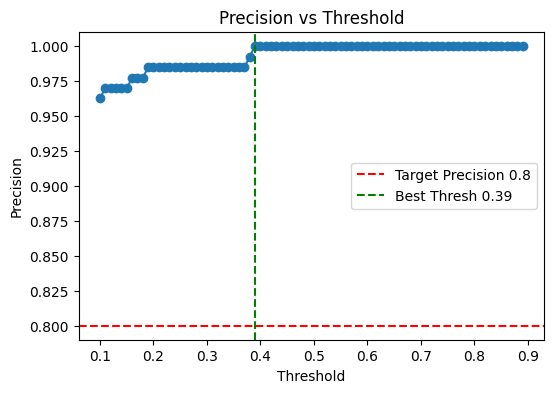

In [39]:
model, best_thresh = train_xgboost_precision(X_train, y_train, X_val, y_val, X_test, y_test, target_precision=0.8)
